# Step 3: Language head and LoRA
### Neeraj, MMAI 894 (router fine-tuning)

**Goal:** two additions to the model from notebook 02, both tested on the same cross-validation folds, the same first-message input, and the same three seeds, so the comparison is like for like.

1. **A language head.** The model also answers "English or French?" (the rest of the system needs the language to reply in the right one). Question: does this extra job change how well it does its main jobs?
2. **LoRA.** Instead of adjusting all 278 million numbers inside the model, freeze them and train only small add-on matrices in the attention layers (about 1% as many numbers, plus the answer heads). Question: is it as accurate, is it steadier from run to run, and is it cheaper? LoRA usually needs a bigger learning step than ordinary fine-tuning, so we try two.

**What the three models are:**

| Name | What changes |
|---|---|
| `baseline` | notebook 02's model: type and escalation heads, ordinary fine-tuning (already run, read from the repo) |
| `full_3heads` | the same, plus the language head |
| `lora_1e4`, `lora_3e4` | LoRA with a learning rate of 1e-4 or 3e-4, with the language head |

**What you need to do:** GPU on (Accelerator: GPU T4), Internet on, run all cells. The long cell takes roughly 30 to 40 minutes; if the session stops, run it again and it carries on. At the end, download the zip listed in the last cell.

Everything shown is computed from saved files; this text holds no results.

## Step 0: Get the latest code and the LoRA library
Fresh clone of the repo (so we run exactly what is on GitHub), plus `peft`, the library that provides LoRA.

In [1]:
import importlib
import os
import shutil
import sys

REPO_URL = "https://github.com/neerajmehla28/northstar-finetuning"
REPO_DIR = "/kaggle/working/northstar-finetuning"

%cd /kaggle/working
if os.path.exists(REPO_DIR):
    shutil.rmtree(REPO_DIR)
!git clone -q {REPO_URL} {REPO_DIR}          # download the repo (public, so no login is needed)
!pip install -q peft                         # LoRA library
!pip uninstall -y -q torchao
    
%cd {REPO_DIR}
sys.path.insert(0, "src")
importlib.invalidate_caches()
for name in [m for m in sys.modules if m.startswith("northstar")]:
    del sys.modules[name]

assert os.path.exists("src/northstar/finetune/train_cv.py"), "code missing: has the latest code been pushed to GitHub?"
assert os.path.exists("results/cv_old_recipe/first_message"), "notebook 02's results are missing from the repo: commit and push results/cv_old_recipe first"
!git log --oneline -3

/kaggle/working
/kaggle/working/northstar-finetuning
15fddb8 (HEAD -> main, origin/main, origin/HEAD) Add language head, LoRA and notebook 03; add notebook 02 results
313227b Add cross-validation harness and notebook 02 (baseline and input comparison)
e6faefe Make notebook 01 always start from a fresh clone


## Step 1: Check the machine and the data

In [2]:
import torch
import pandas as pd
from northstar.finetune import protocol as P
from northstar.finetune.train_cv import TrainConfig, run_cv

print("torch", torch.__version__, "| cuda:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")
assert torch.cuda.is_available(), "No GPU found. Set Accelerator to GPU T4 in the notebook settings."

df = P.load_all()                 # refuses to run if the dataset file is not the exact team file
pool = P.pool(df)                 # the 160 chats; the 40 test chats are not in here
print("Pool:", len(pool), "chats | language labels:", pool["language"].value_counts().to_dict())

torch 2.11.0+cu130 | cuda: True | Tesla T4
Pool: 160 chats | language labels: {'en': 104, 'fr': 56}


## Step 2: Settings
All three new models use the first-message input, the three seeds and 30 epochs, like notebook 02. Only the things in the table above change. The language head adds a third question; LoRA freezes the main model and trains small add-ons with a larger learning step.

In [3]:
OUT = "/kaggle/working/cv_step03"            # one sub-folder per model, one small file per run
RESULTS = "/kaggle/working/results_03"
os.makedirs(RESULTS, exist_ok=True)

VARIANT = "first_message"
SEEDS = P.CV_SEEDS
EPOCHS = 30
HEADS = ("type", "escalation", "language")

CONFIGS = {
    "full_3heads": TrainConfig(epochs=EPOCHS, heads=HEADS),                        # ordinary fine-tuning + language head
    "lora_1e4":    TrainConfig(epochs=EPOCHS, heads=HEADS, lora=True, lr=1e-4),    # LoRA, gentler learning step
    "lora_3e4":    TrainConfig(epochs=EPOCHS, heads=HEADS, lora=True, lr=3e-4),    # LoRA, bigger learning step
}
for name, c in CONFIGS.items():
    print(f"{name:12s} lora={c.lora!s:5s} lr={c.lr} heads={c.heads}")

full_3heads  lora=False lr=2e-05 heads=('type', 'escalation', 'language')
lora_1e4     lora=True  lr=0.0001 heads=('type', 'escalation', 'language')
lora_3e4     lora=True  lr=0.0003 heads=('type', 'escalation', 'language')


## Step 3: Smoke test and time estimate
One fold, one seed, two epochs for each of the three models: proves the whole pipeline (including LoRA) runs end to end before we spend half an hour, and measures how long an epoch takes.

In [4]:
import time

total_s = 0.0
for name, cfg in CONFIGS.items():
    t0 = time.time()
    run_cv(cfg, VARIANT, f"/kaggle/working/smoke/{name}", folds=[0], seeds=[11], epochs=2, verbose=False)
    s = time.time() - t0
    total_s += s
    print(f"{name:12s} smoke test OK: {s:.0f}s for 2 epochs")

n_runs = len(CONFIGS) * len(SEEDS) * P.N_FOLDS
print(f"Full run = {n_runs} runs x {EPOCHS} epochs; rough estimate {total_s / len(CONFIGS) / 2 * EPOCHS * n_runs / 60:.0f} minutes.")

full_3heads  smoke test OK: 10s for 2 epochs


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/kaggle/working/northstar-finetuning/src/northstar/finetune/train_cv.py:161: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  loss_sum += float(loss) * len(chunk)


lora_1e4     smoke test OK: 7s for 2 epochs


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


lora_3e4     smoke test OK: 6s for 2 epochs
Full run = 45 runs x 30 epochs; rough estimate 85 minutes.


## Step 4: The full cross-validation
For each model: every seed, every fold. Each run saves the raw scores of its held-out fold after every epoch. This is the long cell; run it again if the session is interrupted.

In [5]:
for name, cfg in CONFIGS.items():
    print(f"=== {name}")
    run_cv(cfg, VARIANT, f"{OUT}/{name}", seeds=SEEDS)
print("All runs finished.")

=== full_3heads


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[first_message] seed 11 fold 0:    50s | held-out loss at last epoch 1.651


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (126 outputs left out)

[first_message] seed 33 fold 3:    27s | held-out loss at last epoch 1.879


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[first_message] seed 33 fold 4:    27s | held-out loss at last epoch 1.830
All runs finished.


## Step 5: Put the folds back together
As in notebook 02: every chat gets a score from models that never saw it. The baseline (notebook 02, first message) is read from the repo. For each model we find its own best epoch with the same rule as before (smooth the average curve over three epochs, take the best), so each model is judged at its own sensible stopping point.

Best epoch per model: {'baseline': 27, 'full_3heads': 30, 'lora_1e4': 30, 'lora_3e4': 30}


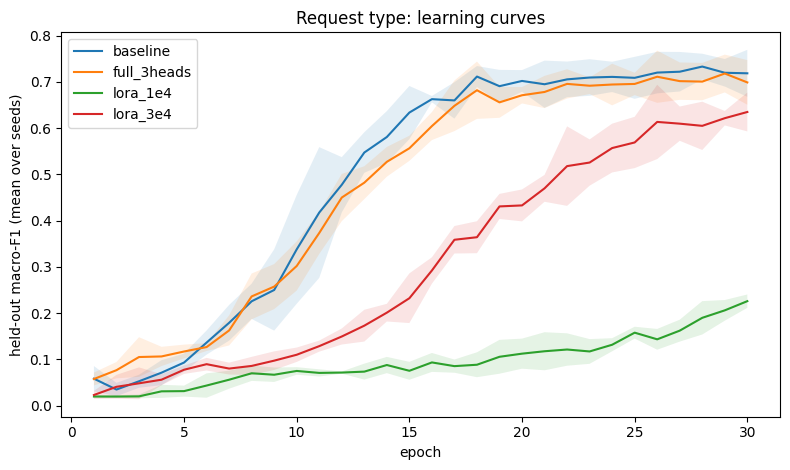

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from northstar.finetune import cv_analysis as A
from northstar.finetune import metrics as M

HEADS_BASE = ("type", "escalation")
sources = {"baseline": ("results/cv_old_recipe", HEADS_BASE)}
sources.update({name: (f"{OUT}/{name}", HEADS) for name in CONFIGS})

runs, oof, curves, best_epoch = {}, {}, {}, {}
for name, (folder, heads) in sources.items():
    runs[name] = A.load_variant(folder, VARIANT)
    oof[name] = A.assemble(runs[name], pool, heads)
    curves[name] = A.epoch_curves(oof[name], pool)
    best_epoch[name], _ = A.pick_epoch(curves[name])
print("Best epoch per model:", best_epoch)

fig, ax = plt.subplots(figsize=(8, 4.8))
for name in sources:
    g = curves[name].groupby("epoch")["type_macro_f1"]
    ax.plot(g.mean().index, g.mean(), label=name)
    ax.fill_between(g.mean().index, g.mean() - g.std(), g.mean() + g.std(), alpha=0.12)
ax.set_xlabel("epoch"); ax.set_ylabel("held-out macro-F1 (mean over seeds)"); ax.set_title("Request type: learning curves"); ax.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS}/learning_curves.png", dpi=150); plt.show()

## Step 6: Results
Mean ± standard deviation over the three seeds, each model at its own best epoch; "ensemble" averages the three seeds' scores before deciding. `trainable numbers` is how many numbers training adjusted; `seconds per run` is the average training time on this GPU.

In [7]:
summ = {n: A.summary_at_epoch(oof[n], pool, best_epoch[n]) for n in sources}

def run_facts(n):
    r = runs[n]
    return (int(np.mean([x["n_trainable"] for x in r])) if "n_trainable" in r[0] else None,
            float(np.mean([x["seconds"] for x in r])) if "seconds" in r[0] else None)

rows, numeric = [], []
for n in sources:
    ps = summ[n]["per_seed"]
    ms = lambda c: f"{ps[c].mean():.3f} ± {ps[c].std():.3f}"
    trainable, secs = run_facts(n)
    et, ee = summ[n]["ensemble_type"], summ[n]["ensemble_escalation"]
    rows.append({"model": n, "epoch": best_epoch[n], "type accuracy": ms("type_accuracy"), "type macro-F1": ms("type_macro_f1"),
                 "escalation recall": ms("esc_recall"), "escalation precision": ms("esc_precision"),
                 "language accuracy": ms("language_accuracy") if "language_accuracy" in ps else "n/a (no head)",
                 "ensemble type acc": f"{et['accuracy']:.3f}",
                 "trainable numbers": f"{trainable:,}" if trainable else "n/a", "seconds per run": f"{secs:.0f}" if secs else "n/a"})
    numeric.append(dict(model=n, epoch=best_epoch[n], trainable=trainable, seconds_per_run=secs,
                        **{f"{c}_mean": ps[c].mean() for c in ps.columns if c != "seed"},
                        **{f"{c}_sd": ps[c].std() for c in ps.columns if c != "seed"},
                        ensemble_type_accuracy=et["accuracy"], ensemble_type_macro_f1=et["macro_f1"],
                        ensemble_esc_recall=ee["recall"], ensemble_esc_precision=ee["precision"]))
table = pd.DataFrame(rows).set_index("model")
pd.DataFrame(numeric).to_csv(f"{RESULTS}/cv_summary_step03.csv", index=False)
table

,epoch,type accuracy,type macro-F1,escalation recall,escalation precision,language accuracy,ensemble type acc,trainable numbers,seconds per run
model,,,,,,,,,
baseline,27,0.721 ± 0.043,0.722 ± 0.043,0.715 ± 0.017,0.857 ± 0.032,n/a (no head),0.787,n/a,n/a
full_3heads,30,0.700 ± 0.051,0.699 ± 0.048,0.734 ± 0.059,0.868 ± 0.016,1.000 ± 0.000,0.744,"278,053,645",54
lora_1e4,30,0.260 ± 0.016,0.226 ± 0.014,0.377 ± 0.091,0.616 ± 0.019,0.992 ± 0.007,0.275,"304,909",27
lora_3e4,30,0.638 ± 0.044,0.635 ± 0.042,0.720 ± 0.008,0.774 ± 0.057,0.998 ± 0.004,0.688,"304,909",27


## Step 7: Is any model really better?
With 160 chats the differences are small, so we ask two things. **Intervals:** the middle 95% of the seed-ensemble accuracy when we resample customers 2,000 times. **Paired tests:** every model against the baseline on the same chats (exact McNemar; a small p-value means the difference is unlikely to be luck). All comparisons are listed, not only favourable ones.

In [8]:
y_type = pool["type_label"].values
customers = pool["customer_id"].values
ens_pred = {n: summ[n]["ensemble_type_logits"].argmax(-1) for n in sources}
correct = {n: ens_pred[n] == y_type for n in sources}

ci_rows = []
for n in sources:
    lo, hi = M.cluster_bootstrap(lambda idx, c=correct[n]: c[idx].mean(), customers, n_boot=2000)
    ci_rows.append(dict(model=n, ensemble_accuracy=correct[n].mean(), ci_low=lo, ci_high=hi))
ci = pd.DataFrame(ci_rows).set_index("model")

pair_rows = []
for n in CONFIGS:
    r = M.mcnemar_exact(correct[n], correct["baseline"])
    pair_rows.append(dict(model=n, versus="baseline", only_model_right=r["only_a_right"], only_baseline_right=r["only_b_right"], p_value=r["p_value"]))
pairs = pd.DataFrame(pair_rows)

ci.round(3).to_csv(f"{RESULTS}/accuracy_intervals_step03.csv"); pairs.to_csv(f"{RESULTS}/comparisons_step03.csv", index=False)
display(ci.round(3)); display(pairs.round(3))

,ensemble_accuracy,ci_low,ci_high
model,,,
baseline,0.788,0.719,0.856
full_3heads,0.744,0.673,0.816
lora_1e4,0.275,0.209,0.344
lora_3e4,0.688,0.613,0.762


,model,versus,only_model_right,only_baseline_right,p_value
0,full_3heads,baseline,3,10,0.092
1,lora_1e4,baseline,4,86,0.000
2,lora_3e4,baseline,8,24,0.007


## Step 8: The language head
How often is the language right, overall and for each language, for the model with the language head at its best epoch (seed ensemble)? The language labels are the dataset's `language` column; French chats include the code-switched ones, which the dataset labels French.

In [9]:
rows = []
for n in CONFIGS:
    arr = oof[n]
    lang_scores = np.mean([a["language"][best_epoch[n] - 1] for a in arr.values()], axis=0)      # average the seeds' scores
    pred = lang_scores.argmax(-1)
    truth = pool["language_label"].values
    for lab, code_ in enumerate(P.LANGUAGES):
        mask = truth == lab
        rows.append(dict(model=n, language=code_, chats=int(mask.sum()), accuracy=float((pred[mask] == lab).mean())))
    rows.append(dict(model=n, language="all", chats=len(truth), accuracy=float((pred == truth).mean())))
lang_table = pd.DataFrame(rows)
lang_table.round(3).to_csv(f"{RESULTS}/language_accuracy.csv", index=False)
lang_table.pivot(index="model", columns="language", values="accuracy").round(3)

language,all,en,fr
model,,,
full_3heads,1.000,1.000,1.0
lora_1e4,0.988,0.981,1.0
lora_3e4,1.000,1.000,1.0


## Step 9: Save the results
The zip holds the raw scores of every run, so any later question can be answered without retraining. Download `cv_step03.zip` and the tables and figures from the `results_03` folder, and tell me.

In [10]:
shutil.make_archive(f"{RESULTS}/cv_step03", "zip", OUT)
for name in sorted(os.listdir(RESULTS)):
    print(f"{name:40s} {os.path.getsize(os.path.join(RESULTS, name)) / 1024:8.0f} KB")

accuracy_intervals_step03.csv                   0 KB
comparisons_step03.csv                          0 KB
cv_step03.zip                                1369 KB
cv_summary_step03.csv                           2 KB
language_accuracy.csv                           0 KB
learning_curves.png                           125 KB


## What this notebook shows, and its limits
- **Shows:** whether adding the language head changes the main jobs, whether LoRA matches ordinary fine-tuning in accuracy, run-to-run steadiness and training cost, and how well the language is recognised. Read the tables; this text holds no numbers.
- **Limits:**
  - 160 chats and 3 seeds: small differences are inside the noise, which is why intervals and paired tests are shown.
  - LoRA was tried at two learning rates only; a different setting could change its standing.
  - Each model is judged at its own best epoch, chosen on the same folds it is scored on (very slightly optimistic for all models alike).
  - Language is easy in this synthetic data (the chats are cleanly English or French); real mixed-language chats would be harder.
  - Still the first-message input only, still the original training recipe otherwise, and still one generator behind all the chats.